# Ratio Metrics & the Delta Method

Many product metrics are ratios: conversion per session, spend per visit, clicks per page view. In these metrics
the **analysis unit** (session, visit, page view) differs from the **randomization unit** (the user). One user
produces many sessions, and the sessions of one user are not independent. A t-test that treats every session as
an independent row underestimates the variance and reports too many false positives.

The **delta method** gives the correct variance of a ratio of two user-level means. This lesson derives it,
applies it to real and synthetic data, and checks it with a bootstrap and an A/A simulation.

**After this lesson you can:**

1. Identify a ratio metric and its randomization unit.
2. Derive the delta-method variance of a ratio of means with a first-order Taylor expansion.
3. Show with an A/A simulation that a session-level t-test has an inflated false positive rate.
4. Compute a CI for the relative lift with the delta method, Fieller's method and a user-level bootstrap.
5. Cross-check the result with `tt.RatioOfMeans` in tea-tasting.

**Data:** Hillstrom MineThatData E-Mail Analytics challenge (2008): 64,000 customers in a randomized e-mail test.
Sections 3 to 6 add simulated sessions to the real customers (a synthetic panel, described in section 3).
**Services:** none.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tea_tasting as tt
from scipy import stats

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: pinned datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
pd.set_option("display.width", 130)
warnings.filterwarnings("ignore", category=FutureWarning)

df = pd.read_csv(datasets.fetch("hillstrom_email.csv"))
CONTROL, TREAT = "No E-Mail", "Womens E-Mail"
ab = df[df.segment.isin([CONTROL, TREAT])].reset_index(drop=True)
Z = stats.norm.ppf(0.975)
rng = np.random.default_rng(14)
print(ab.groupby("segment")[["visit", "spend"]].agg(["sum", "count"]).reindex([CONTROL, TREAT]).to_string())

              visit            spend       
                sum  count       sum  count
segment                                    
No E-Mail      2262  21306  13908.33  21306
Womens E-Mail  3238  21387  23038.11  21387


The lesson uses the Womens E-Mail arm (treatment) and the No E-Mail arm (control), as in lesson 03.

## 1. Ratio Metrics and the Delta Method

A **ratio metric** divides the sum of a numerator over all users by the sum of a denominator over all users. For
user $i$ in one arm, let $Y_i$ be the numerator (for example orders) and $X_i$ the denominator (for example
sessions). Then

$$\hat R = \frac{\sum_i Y_i}{\sum_i X_i} = \frac{\bar Y}{\bar X} .$$

Both $\bar Y$ and $\bar X$ are means of independent user rows, so the central limit theorem applies to them. The
ratio is a nonlinear function $f(\bar Y, \bar X) = \bar Y / \bar X$. A first-order Taylor expansion around the true
means $(\mu_Y, \mu_X)$ makes it linear:

$$\hat R \approx \frac{\mu_Y}{\mu_X} + \frac{1}{\mu_X}(\bar Y - \mu_Y) - \frac{\mu_Y}{\mu_X^2}(\bar X - \mu_X) .$$

The variance of a linear combination follows from the variances and the covariance of $\bar Y$ and $\bar X$.
With $R = \mu_Y/\mu_X$ and $\operatorname{Var}(\bar Y) = \sigma_Y^2/n$:

$$\operatorname{Var}(\hat R) \approx \frac{1}{n\,\mu_X^2}\left(\sigma_Y^2 - 2R\,\sigma_{XY} + R^2 \sigma_X^2\right) .$$

This is the **delta method**. Replace the true values by the sample values to estimate it. The variance of the
difference between two independent arms is $\operatorname{Var}(\hat R_T) + \operatorname{Var}(\hat R_C)$.

The **naive method** puts one row per session into a t-test. It uses $n$ = number of sessions and the variance
between sessions. That is correct only if the sessions are independent.

In [2]:
def ratio_stats(num: np.ndarray, den: np.ndarray) -> dict:
    """Ratio of means R = mean(num) / mean(den) over randomization units, and its delta-method variance."""
    n = len(num)
    mx, my = den.mean(), num.mean()
    r = my / mx
    v_y, v_x = num.var(ddof=1), den.var(ddof=1)
    c_xy = np.cov(num, den, ddof=1)[0, 1]
    var_r = (v_y - 2 * r * c_xy + r ** 2 * v_x) / (n * mx ** 2)
    return {"R": r, "var": var_r, "n_units": n, "n_rows": den.sum()}

def compare(t: dict, c: dict) -> dict:
    """Absolute difference of two independent ratios with a normal 95 % CI and a two-sided p-value."""
    d, se = t["R"] - c["R"], np.sqrt(t["var"] + c["var"])
    return {"diff": d, "se": se, "lo": d - Z * se, "hi": d + Z * se, "p": 2 * stats.norm.sf(abs(d) / se)}

## 2. Real Data: Spend per Visit

In Hillstrom, `visit` is 0 or 1 for each customer. **Spend per visit** is $\sum \text{spend} / \sum \text{visit}$:
the mean spend of the customers who visited.

In [3]:
arm = {g: ab[ab.segment == g] for g in [CONTROL, TREAT]}
spv = {g: ratio_stats(arm[g].spend.to_numpy(dtype=float), arm[g].visit.to_numpy(dtype=float)) for g in arm}
delta = compare(spv[TREAT], spv[CONTROL])

vis = {g: arm[g].loc[arm[g].visit == 1, "spend"].to_numpy(dtype=float) for g in arm}   # one row per visitor
naive = stats.ttest_ind(vis[TREAT], vis[CONTROL], equal_var=False)
se_naive = np.sqrt(vis[TREAT].var(ddof=1) / len(vis[TREAT]) + vis[CONTROL].var(ddof=1) / len(vis[CONTROL]))

for g in arm:
    print(f"{g:14s} spend per visit = ${spv[g]['R']:.3f} ({spv[g]['n_rows']:.0f} visitors of {spv[g]['n_units']} users)")
print(f"delta method (all users): diff = ${delta['diff']:.3f}, SE = {delta['se']:.4f}, p = {delta['p']:.3f}")
print(f"Welch t-test on visitors: diff = ${vis[TREAT].mean() - vis[CONTROL].mean():.3f}, SE = {se_naive:.4f}, "
      f"p = {naive.pvalue:.3f}")

No E-Mail      spend per visit = $6.149 (2262 visitors of 21306 users)
Womens E-Mail  spend per visit = $7.115 (3238 visitors of 21387 users)
delta method (all users): diff = $0.966, SE = 0.9985, p = 0.333
Welch t-test on visitors: diff = $0.966, SE = 0.9987, p = 0.333


Here the delta method and the Welch t-test on the visitors give the same SE (0.9985 and 0.9987). This is correct:
each customer has at most one visit, so each visitor row is one independent user. The analysis unit and the
randomization unit are the same.

There is a second problem. The e-mail changes **who** visits: 3,238 treatment visitors against 2,262 control
visitors. The visitors in the two arms are different groups of people. So spend per visit is a valid metric to
monitor. But its lift is not the causal effect of the e-mail on a fixed group of customers. Report it next to
spend per user (lesson 03), which has no such problem.

## 3. A Synthetic Multi-Session Panel

Hillstrom has no session data, so this section **simulates** sessions for the real customers. It keeps the real
arm and the real `visit` flag of each customer. The simulation adds two things:

1. Each visitor gets $1 + \text{Poisson}(\lambda_i)$ sessions, with $\lambda_i \sim \text{Gamma}$ (mean 3). Some
   users return often, most return a few times.
2. Each session converts with a user-level probability $p_i \sim \text{Beta}$, with the mean equal to the real
   conversions per visitor of the arm. A few users buy often, most never buy.

These are assumptions. They copy two facts of real web data: a heavy-tailed number of sessions per user, and
users who differ in how often they buy.

In [4]:
EXTRA_SESSIONS, GAMMA_SHAPE, BETA_A = 3.0, 0.5, 0.3       # simulation parameters (assumptions)

def make_panel(data: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
    """Synthetic sessions for real Hillstrom users: visitors get 1 + Poisson(lambda_u) sessions,
    and every session converts with a user-level probability p_u (Beta, mean = real conversions per visitor)."""
    out = []
    for g, d in data.groupby("segment"):
        v = d.visit.to_numpy()
        lam = rng.gamma(GAMMA_SHAPE, EXTRA_SESSIONS / GAMMA_SHAPE, len(d))   # heavy users visit more often
        sessions = v * (1 + rng.poisson(lam))
        p_mean = d.conversion.sum() / d.visit.sum()                          # real rate per visitor in this arm
        p_user = rng.beta(BETA_A, BETA_A * (1 - p_mean) / p_mean, len(d))     # some users buy often, most never
        out.append(pd.DataFrame({"user": d.index, "segment": g, "sessions": sessions,
                                 "orders": rng.binomial(sessions, p_user)}))
    return pd.concat(out).sort_values("user").reset_index(drop=True)   # same row order as the input

users = make_panel(ab, rng)                                   # one row per user (randomization unit)
sessions = users.loc[users.index.repeat(users.sessions)].reset_index(drop=True)   # one row per session
sessions["converted"] = 0
first = sessions.groupby("user").cumcount() < sessions.groupby("user")["orders"].transform("first")
sessions.loc[first, "converted"] = 1                          # the first `orders` sessions of a user convert
print(f"users: {len(users):,} | sessions: {len(sessions):,} | orders: {sessions.converted.sum():,}")
print(users[users.sessions > 0].groupby("segment")[["sessions", "orders"]].describe()
      .loc[:, (slice(None), ["mean", "50%", "max"])].round(2).to_string())
top = users.sort_values("sessions", ascending=False)
print(f"top 10 % of visitors by sessions hold {100 * top.sessions.head(int(0.1 * (users.sessions > 0).sum())).sum() / users.sessions.sum():.0f} % of sessions")

users: 42,693 | sessions: 22,174 | orders: 1,298
              sessions            orders           
                  mean  50%   max   mean  50%   max
segment                                            
No E-Mail         4.08  2.0  43.0   0.21  0.0   9.0
Womens E-Mail     4.00  2.0  39.0   0.26  0.0  15.0
top 10 % of visitors by sessions hold 37 % of sessions


The panel has 22,174 sessions and 1,298 orders. The median visitor has 2 sessions, the maximum is 43, and the top
10 % of visitors hold 37 % of all sessions.

## 4. Naive Session-Level Test vs Delta Method

The metric is **conversion per session**: orders / sessions. The naive test uses one row per session with a 0/1
`converted` value. The delta method uses one row per user with the columns `orders` and `sessions`.

In [5]:
naive_rows = {g: sessions.loc[sessions.segment == g, "converted"].to_numpy(dtype=float) for g in [CONTROL, TREAT]}
t_naive = stats.ttest_ind(naive_rows[TREAT], naive_rows[CONTROL], equal_var=False)
se_n = np.sqrt(sum(x.var(ddof=1) / len(x) for x in naive_rows.values()))

cps = {g: ratio_stats(users.loc[users.segment == g, "orders"].to_numpy(dtype=float),
                      users.loc[users.segment == g, "sessions"].to_numpy(dtype=float)) for g in [CONTROL, TREAT]}
d_cps = compare(cps[TREAT], cps[CONTROL])

print(f"conversion per session: control {cps[CONTROL]['R']:.4f}, treatment {cps[TREAT]['R']:.4f}, "
      f"diff {d_cps['diff']:.4f}")
print(f"naive (sessions as rows): SE = {se_n:.5f}, p = {t_naive.pvalue:.4f}")
print(f"delta method (users):     SE = {d_cps['se']:.5f}, p = {d_cps['p']:.4f}")
print(f"SE ratio delta / naive = {d_cps['se'] / se_n:.2f}  ->  variance ratio (design effect) = {(d_cps['se'] / se_n) ** 2:.2f}")

conversion per session: control 0.0512, treatment 0.0638, diff 0.0126
naive (sessions as rows): SE = 0.00314, p = 0.0001
delta method (users):     SE = 0.00501, p = 0.0121
SE ratio delta / naive = 1.59  ->  variance ratio (design effect) = 2.54


Both methods give the same point estimate (+0.0126), because the ratio of sums does not depend on the row
format. The SE is different. The delta-method SE (0.00501) is 1.59 times the naive SE (0.00314). So the true
variance is 2.54 times larger than the naive one. This factor is the **design effect**. For clusters of equal size
$m$ with intra-user correlation $\rho$, it is $1 + (m-1)\rho$.

The naive test reports p = 0.0001; the correct p-value is 0.0121. The conclusion is the same here, but the naive
CI is 37 % too narrow. For a smaller effect, the naive test reports a "significant" result that is noise.

tea-tasting implements the same formula in `tt.RatioOfMeans(numer, denom)`. The cell uses `use_t=False` so that
the test uses the normal distribution, as the hand formulas do.

In [6]:
experiment = tt.Experiment(
    conv_per_session=tt.RatioOfMeans("orders", "sessions", use_t=False),     # z-test, as in the hand formulas
    spend_per_visit=tt.RatioOfMeans("spend", "visit", use_t=False),
    variant="segment",
)
assert (users.user.to_numpy() == ab.index.to_numpy()).all()             # one row per user, same order as ab
res = experiment.analyze(users.assign(spend=ab.spend.to_numpy(), visit=ab.visit.to_numpy()), control=CONTROL)
print(res.with_keys(("metric", "control", "treatment", "effect_size", "effect_size_ci", "pvalue")))
r = res.to_pandas().set_index("metric")
print(f"|tea-tasting - by hand|: conv_per_session CI lower {abs(r.loc['conv_per_session', 'effect_size_ci_lower'] - d_cps['lo']):.1e}, "
      f"p {abs(r.loc['conv_per_session', 'pvalue'] - d_cps['p']):.1e} | spend_per_visit p "
      f"{abs(r.loc['spend_per_visit', 'pvalue'] - delta['p']):.1e}")

metric           control treatment effect_size    effect_size_ci pvalue
conv_per_session  0.0512    0.0638      0.0126 [0.00275, 0.0224] 0.0121
spend_per_visit     6.15      7.11       0.966    [-0.991, 2.92]  0.333
|tea-tasting - by hand|: conv_per_session CI lower 1.7e-18, p 2.3e-17 | spend_per_visit p 3.3e-16


*Insight: tea-tasting and the hand formula agree to 1e-16 or better for both ratio metrics. The input is one row per user
with the numerator and the denominator as columns: the randomization unit stays the analysis row.*

## 5. CI for the Relative Lift: Delta, Fieller, Bootstrap

The relative lift is $\hat R_T / \hat R_C - 1$, a ratio of two ratios. Four ways to get its CI:

| method | idea |
| :--- | :--- |
| delta | second delta method on $q = \hat R_T/\hat R_C$; symmetric CI |
| delta on log | delta method on $\log q$, then exponentiate; asymmetric CI (tea-tasting default) |
| Fieller | exact inversion of a test for $a - \theta b = 0$; no Taylor expansion |
| user bootstrap | resample **whole users** with replacement, 2,000 times; percentile CI |

**Fieller's method** finds all $\theta$ for which $(a - \theta b)/\sqrt{v_a + \theta^2 v_b}$ is not significant,
with $a = \hat R_T$ and $b = \hat R_C$. Squared, this is a quadratic equation in $\theta$:

$$(b^2 - z^2 v_b)\,\theta^2 - 2ab\,\theta + (a^2 - z^2 v_a) = 0 .$$

If $b^2 > z^2 v_b$ (the control ratio is clearly not 0), the two roots are the CI limits. A bootstrap must
resample users, not sessions. Otherwise it repeats the error of the naive test.

In [7]:
def fieller(a, va, b, vb, z=Z):
    """CI for theta = a / b with independent normal a, b (Fieller 1954). Returns (lo, hi) or None if unbounded."""
    den = b ** 2 - z ** 2 * vb
    if den <= 0:
        return None                                    # b is not significantly different from 0
    disc = np.sqrt(a ** 2 * vb + b ** 2 * va - z ** 2 * va * vb)
    return (a * b - z * disc) / den, (a * b + z * disc) / den

def boot_ratio(num, den, b, rng):
    """User-level (cluster) bootstrap of sum(num) / sum(den): resample whole users with replacement."""
    n = len(num)
    out = np.empty(b)
    for i in range(b):
        idx = rng.integers(0, n, n)
        out[i] = num[idx].sum() / den[idx].sum()
    return out

def relative_cis(num_t, den_t, num_c, den_c, b=2000):
    t, c = ratio_stats(num_t, den_t), ratio_stats(num_c, den_c)
    q = t["R"] / c["R"]
    se_q = np.sqrt(t["var"] / c["R"] ** 2 + t["R"] ** 2 * c["var"] / c["R"] ** 4)
    se_log = np.sqrt(t["var"] / t["R"] ** 2 + c["var"] / c["R"] ** 2)
    f = fieller(t["R"], t["var"], c["R"], c["var"])
    bt = boot_ratio(num_t, den_t, b, rng) / boot_ratio(num_c, den_c, b, rng)
    return pd.DataFrame({
        "delta":          [q - Z * se_q, q + Z * se_q],
        "delta on log":   [q * np.exp(-Z * se_log), q * np.exp(Z * se_log)],
        "Fieller":        list(f),
        "user bootstrap": list(np.percentile(bt, [2.5, 97.5])),
    }, index=["lo", "hi"]).T.sub(1).mul(100).assign(width=lambda x: x.hi - x.lo), q - 1

t0 = time.perf_counter()
u = {g: users[users.segment == g] for g in [CONTROL, TREAT]}
rel_cps, q_cps = relative_cis(*(u[g][c].to_numpy(dtype=float) for g in [TREAT, CONTROL] for c in ["orders", "sessions"]))
rel_spv, q_spv = relative_cis(*(arm[g][c].to_numpy(dtype=float) for g in [TREAT, CONTROL] for c in ["spend", "visit"]))
print(f"conversion per session (synthetic panel): relative lift {100 * q_cps:+.1f} %")
print(rel_cps.round(1).to_string())
print(f"\nspend per visit (real Hillstrom): relative lift {100 * q_spv:+.1f} %")
print(rel_spv.round(1).to_string())
print(f"\nbootstrap time: {time.perf_counter() - t0:.1f} s")

conversion per session (synthetic panel): relative lift +24.6 %
                 lo    hi  width
delta           3.0  46.1   43.1
delta on log    4.8  48.1   43.3
Fieller         4.9  48.6   43.7
user bootstrap  5.1  49.1   44.0

spend per visit (real Hillstrom): relative lift +15.7 %
                  lo    hi  width
delta          -18.9  50.4   69.3
delta on log   -14.2  56.1   70.3
Fieller        -13.8  58.8   72.6
user bootstrap -15.3  56.5   71.8

bootstrap time: 1.0 s


For conversion per session the four CIs are close: the widths are 43.1 to 44.0 percentage points. For the real
spend per visit the metric is noisier, and the methods differ more. The symmetric delta CI [-18.9 %, 50.4 %] is
shifted to the left of the three others. The log version, Fieller and the bootstrap agree within a few points
([-14.2 %, 56.1 %], [-13.8 %, 58.8 %], [-15.3 %, 56.5 %]). The right panel of the plot in section 6 shows these
four intervals.

*Insight: A ratio of positive values has a right-skewed sampling distribution. The symmetric delta CI ignores
this skew. Use the log version or Fieller for the relative lift, and a user-level bootstrap to check.*

## 6. A/A Simulation: the False Positive Rate

In an **A/A test** both halves get the same treatment, so every significant result is a false positive. A correct
test at $\alpha = 0.05$ has a false positive rate (FPR) of 5 %.

The simulation takes the 21,306 control users of the panel and splits them at random into two halves, 2,000
times. Each split is one A/A test. The cell computes both tests for all splits with matrix products, without a
Python loop over the splits.

In [8]:
def aa_fpr(panel: pd.DataFrame, n_sims: int, rng: np.random.Generator, chunk: int = 500) -> dict:
    """A/A test: split the users of one arm at random into two halves, n_sims times.
    Sufficient statistics per half come from one matrix product, so no Python loop over simulations."""
    s = panel.sessions.to_numpy(dtype=float); o = panel.orders.to_numpy(dtype=float)
    X = np.column_stack([s, o, s * s, o * o, s * o])
    tot, n = X.sum(0), len(s)
    hits = {"naive (sessions)": [], "delta method (users)": []}
    widths = {k: [] for k in hits}
    for _ in range(n_sims // chunk):
        A = (rng.random((chunk, n)) < 0.5).astype(np.float64)
        nA = A.sum(1)
        res = []
        for M, k in [(A @ X, nA), (tot - A @ X, n - nA)]:
            ms, mo = M[:, 0] / k, M[:, 1] / k
            vs, vo = (M[:, 2] - k * ms ** 2) / (k - 1), (M[:, 3] - k * mo ** 2) / (k - 1)
            cov = (M[:, 4] - k * ms * mo) / (k - 1)
            R = mo / ms
            var_delta = (vo - 2 * R * cov + R ** 2 * vs) / (k * ms ** 2)
            var_naive = R * (1 - R) / M[:, 0]            # Bernoulli variance with sessions as rows
            res.append((R, var_naive, var_delta))
        diff = res[0][0] - res[1][0]
        for j, key in [(1, "naive (sessions)"), (2, "delta method (users)")]:
            se = np.sqrt(res[0][j] + res[1][j])
            hits[key].append(np.abs(diff) / se > Z)
            widths[key].append(2 * Z * se)
    return {k: (np.concatenate(v).mean(), np.concatenate(widths[k]).mean()) for k, v in hits.items()}

N_SIMS = 2000
control_panel = users[users.segment == CONTROL]
t0 = time.perf_counter()
fpr = aa_fpr(control_panel, N_SIMS, rng)
mc = Z * np.sqrt(0.05 * 0.95 / N_SIMS)
for k, (f, w) in fpr.items():
    print(f"{k:22s} false positive rate = {100 * f:5.2f} %   mean CI width = {100 * w:.2f} pp")
print(f"expected if correct: 5.00 % +/- {100 * mc:.2f} (Monte Carlo 95 % band) | {time.perf_counter() - t0:.1f} s")

naive (sessions)       false positive rate = 18.65 %   mean CI width = 1.80 pp
delta method (users)   false positive rate =  5.30 %   mean CI width = 2.69 pp
expected if correct: 5.00 % +/- 0.96 (Monte Carlo 95 % band) | 0.5 s


The naive test rejects the true null hypothesis in 18.65 % of the A/A tests, almost four times the nominal 5 %.
The delta method gives 5.30 %, inside the Monte Carlo band of 5 % ± 0.96 points. The naive CI is narrower
(1.80 against 2.69 percentage points): it is narrow because it is wrong.

The next cell repeats the simulation for panels with more or fewer sessions per visitor.

In [9]:
sweep = []
for extra in [0.0, 1.0, 3.0, 6.0]:                     # mean number of extra sessions per visitor
    EXTRA_SESSIONS = extra
    p = make_panel(ab[ab.segment == CONTROL], np.random.default_rng(100 + int(extra)))
    f = aa_fpr(p, N_SIMS, rng)
    sweep.append({"mean sessions per visitor": 1 + extra,
                  "naive FPR %": 100 * f["naive (sessions)"][0], "delta FPR %": 100 * f["delta method (users)"][0]})
EXTRA_SESSIONS = 3.0
sweep = pd.DataFrame(sweep)
print(sweep.round(2).to_string(index=False))

 mean sessions per visitor  naive FPR %  delta FPR %
                       1.0         6.55         6.55
                       2.0         8.05         4.80
                       4.0        18.90         5.15
                       7.0        28.75         5.35


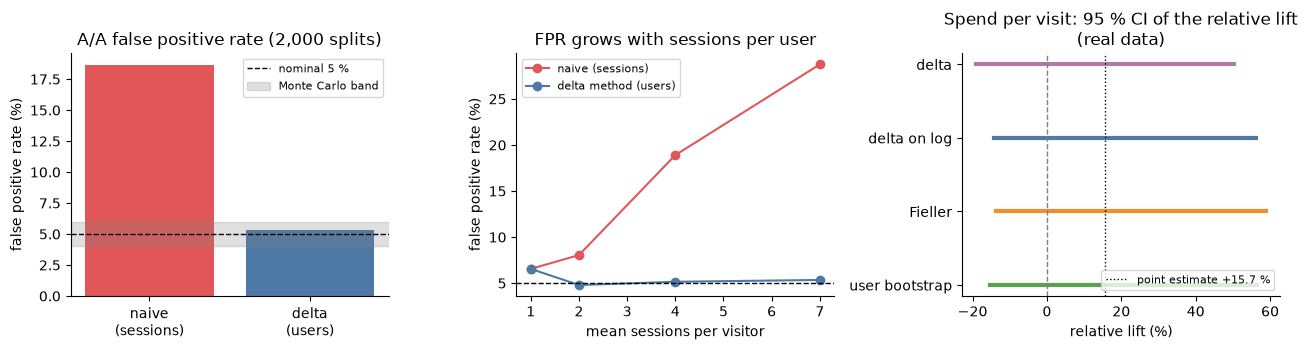

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
names = list(fpr)
ax[0].bar(["naive\n(sessions)", "delta\n(users)"], [100 * fpr[k][0] for k in names], color=["#E15759", "#4E79A7"])
ax[0].axhline(5, color="black", ls="--", lw=1, label="nominal 5 %")
ax[0].axhspan(100 * (0.05 - mc), 100 * (0.05 + mc), color="grey", alpha=0.25, label="Monte Carlo band")
ax[0].set(title=f"A/A false positive rate ({N_SIMS:,} splits)", ylabel="false positive rate (%)")
ax[0].legend(fontsize=8)

ax[1].plot(sweep["mean sessions per visitor"], sweep["naive FPR %"], "o-", color="#E15759", label="naive (sessions)")
ax[1].plot(sweep["mean sessions per visitor"], sweep["delta FPR %"], "o-", color="#4E79A7", label="delta method (users)")
ax[1].axhline(5, color="black", ls="--", lw=1)
ax[1].set(title="FPR grows with sessions per user", xlabel="mean sessions per visitor", ylabel="false positive rate (%)")
ax[1].legend(fontsize=8)

tab = rel_spv.iloc[::-1]
for i, (name, row) in enumerate(tab.iterrows()):
    ax[2].plot([row.lo, row.hi], [i, i], lw=3, color=["#59A14F", "#F28E2B", "#4E79A7", "#B07AA1"][i])
ax[2].axvline(100 * q_spv, color="black", ls=":", lw=1, label=f"point estimate {100 * q_spv:+.1f} %")
ax[2].axvline(0, color="grey", ls="--", lw=1)
ax[2].set_yticks(range(len(tab)), tab.index)
ax[2].set(title="Spend per visit: 95 % CI of the relative lift\n(real data)", xlabel="relative lift (%)")
ax[2].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

With one session per visitor the two methods are identical (6.55 %), because each session is one user. This
value is slightly above the Monte Carlo band: each half has only about 60 orders, so the normal approximation is
not exact. With 2, 4 and 7 sessions per visitor, the naive FPR grows to 8.05 %, 18.90 % and 28.75 %. The delta
method stays between 4.80 % and 5.35 %.

*Insight: The error of the naive test grows with the number of rows per randomization unit. The delta method
keeps the FPR at 5 % for every panel, because it computes the variance over the independent units.*

| approach | valid? | when to use |
| :--- | :--- | :--- |
| t-test on session rows | no, if users have several sessions | never for user-randomized tests |
| delta method on user rows | yes | default for ratio metrics; fast, needs only sums |
| user-level (cluster) bootstrap | yes | check of the delta method; small samples; skewed metrics |
| mean of per-user ratios | yes, but a different metric | when each user must count equally (users with 0 sessions drop out) |
| change the randomization unit to sessions | yes, if sessions are independent | rare: one user then sees both arms |

## Real-World Use Case

Microsoft's experimentation team documented the problem and the solution in a KDD 2018 paper. The paper is
Deng, Knoblich and Lu, *Applying the Delta Method in Metric Analytics: A Practical Guide with Novel Ideas*. The paper shows that
page-level and session-level metrics in user-randomized tests need the delta method. It also shows how the method
extends to the CI of a relative lift. The tea-tasting documentation cites this paper as the reference for
`tt.RatioOfMeans`.

A platform needs only a few sums per user and arm: $\sum Y$, $\sum X$, $\sum Y^2$, $\sum X^2$, $\sum XY$ and
$n$. A data warehouse computes these with one `GROUP BY` query, so the delta method scales to billions of
sessions. Lesson 05 (CUPED) uses the same sums with a pre-experiment covariate to reduce the variance.